# 多层感知机的从零开始实现
:label:`sec_mlp_scratch`

我们已经在 :numref:`sec_mlp`中描述了多层感知机（MLP），
现在让我们尝试自己实现一个多层感知机。
为了与之前softmax回归（ :numref:`sec_softmax_scratch` ）
获得的结果进行比较，
我们将继续使用Fashion-MNIST图像分类数据集
（ :numref:`sec_fashion_mnist`）。


In [1]:
import torch
from torch import nn
from d2l import torch as d2l

In [2]:
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)

## 初始化模型参数

回想一下，Fashion-MNIST中的每个图像由
$28 \times 28 = 784$个灰度像素值组成。
所有图像共分为10个类别。
忽略像素之间的空间结构，
我们可以将每个图像视为具有784个输入特征
和10个类的简单分类数据集。
首先，我们将[**实现一个具有单隐藏层的多层感知机，
它包含256个隐藏单元**]。
注意，我们可以将这两个变量都视为超参数。
通常，我们选择2的若干次幂作为层的宽度。
因为内存在硬件中的分配和寻址方式，这么做往往可以在计算上更高效。

我们用几个张量来表示我们的参数。
注意，对于每一层我们都要记录一个权重矩阵和一个偏置向量。
跟以前一样，我们要为损失关于这些参数的梯度分配内存。


In [4]:
# 定义输入层、输出层和隐藏层的神经元数量
num_inputs, num_outputs, num_hiddens = 784, 10, 256

# 第一层权重：784个输入特征 → 256个隐藏神经元
W1 = nn.Parameter(torch.randn(
    num_inputs, num_hiddens, requires_grad=True) * 0.01)

# 第一层偏置：256个隐藏神经元对应256个偏置
b1 = nn.Parameter(torch.zeros(num_hiddens, requires_grad=True))

# 第二层权重：256个隐藏神经元 → 10个输出类别
W2 = nn.Parameter(torch.randn(
    num_hiddens, num_outputs, requires_grad=True) * 0.01)

# 第二层偏置：10个输出类别对应10个偏置
b2 = nn.Parameter(torch.zeros(num_outputs, requires_grad=True))

# 保存所有可训练参数
params = [W1, b1, W2, b2]

## 激活函数

为了确保我们对模型的细节了如指掌，
我们将[**实现ReLU激活函数**]，
而不是直接调用内置的`relu`函数。


In [5]:
def relu(X):
    """实现ReLU激活函数"""
    a = torch.zeros_like(X)  # 创建与X形状相同的全零张量
    return torch.max(X, a)   # 逐元素取最大值，将负数置为0

$$
\underbrace{X}_{784维输入}
\xrightarrow{W_1,b_1}
\underbrace{H}_{256维隐藏层}
\xrightarrow{\mathrm{ReLU}}
\underbrace{H'}_{256维激活输出}
\xrightarrow{W_2,b_2}
\underbrace{O}_{10维输出}
$$

## 模型

因为我们忽略了空间结构，
所以我们使用`reshape`将每个二维图像转换为一个长度为`num_inputs`的向量。
只需几行代码就可以(**实现我们的模型**)。


In [8]:
def net(X):
    """定义单隐藏层多层感知机（MLP）"""
    X = X.reshape((-1, num_inputs))  # 将图像展平为784维向量
    H = relu(X @ W1 + b1)            # 隐藏层：线性变换 + ReLU激活
    return H @ W2 + b2               # 输出层：计算10个类别的预测分数

## 损失函数

由于我们已经从零实现过softmax函数（ :numref:`sec_softmax_scratch`），
因此在这里我们直接使用高级API中的内置函数来计算softmax和交叉熵损失。
回想一下我们之前在 :numref:`subsec_softmax-implementation-revisited`中
对这些复杂问题的讨论。
我们鼓励感兴趣的读者查看损失函数的源代码，以加深对实现细节的了解。


In [9]:
# 使用交叉熵损失函数，返回每个样本的损失
loss = nn.CrossEntropyLoss(reduction='none')

## 训练

幸运的是，[**多层感知机的训练过程与softmax回归的训练过程完全相同**]。
可以直接调用`d2l`包的`train_ch3`函数（参见 :numref:`sec_softmax_scratch` ），
将迭代周期数设置为10，并将学习率设置为0.1.


In [12]:
def train_ch3(net, train_iter, test_iter, loss, num_epochs, updater):
    """训练多层感知机模型"""
    for epoch in range(num_epochs):
        train_loss, train_correct, train_total = 0.0, 0, 0

        for X, y in train_iter:
            y_hat = net(X)           # 前向传播
            l = loss(y_hat, y)       # 计算损失

            updater.zero_grad()      # 清空梯度
            l.mean().backward()      # 反向传播
            updater.step()           # 更新参数

            train_loss += l.sum().item()
            train_correct += (y_hat.argmax(dim=1) == y).sum().item()
            train_total += y.numel()

        # 计算测试集准确率
        test_correct, test_total = 0, 0

        with torch.no_grad():
            for X, y in test_iter:
                y_hat = net(X)
                test_correct += (y_hat.argmax(dim=1) == y).sum().item()
                test_total += y.numel()

        print(f"Epoch {epoch + 1}: "
              f"loss={train_loss / train_total:.4f}, "
              f"train_acc={train_correct / train_total:.4f}, "
              f"test_acc={test_correct / test_total:.4f}")

In [13]:
num_epochs, lr = 10, 0.1  # 训练10轮，学习率为0.1

# 定义随机梯度下降优化器
updater = torch.optim.SGD(params, lr=lr)

# 调用自定义训练函数
train_ch3(net, train_iter, test_iter, loss, num_epochs, updater)

Epoch 1: loss=1.0405, train_acc=0.6471, test_acc=0.7609
Epoch 2: loss=0.5984, train_acc=0.7903, test_acc=0.7850
Epoch 3: loss=0.5196, train_acc=0.8186, test_acc=0.8155
Epoch 4: loss=0.4836, train_acc=0.8304, test_acc=0.8065
Epoch 5: loss=0.4539, train_acc=0.8406, test_acc=0.8264
Epoch 6: loss=0.4337, train_acc=0.8466, test_acc=0.8303
Epoch 7: loss=0.4170, train_acc=0.8526, test_acc=0.8393
Epoch 8: loss=0.4056, train_acc=0.8561, test_acc=0.8430
Epoch 9: loss=0.3940, train_acc=0.8605, test_acc=0.8376
Epoch 10: loss=0.3826, train_acc=0.8642, test_acc=0.8536


为了对学习到的模型进行评估，我们将[**在一些测试数据上应用这个模型**]。


In [16]:
import matplotlib.pyplot as plt

def predict_ch3(net, test_iter, n=6):
    """预测并展示前6张测试图片"""
    X, y = next(iter(test_iter))  # 获取一个批次的测试数据

    with torch.no_grad():  # 禁用梯度计算
        y_hat = net(X).argmax(dim=1)  # 获取预测类别

    # 将类别编号转换为服饰名称
    trues = d2l.get_fashion_mnist_labels(y[:n])
    preds = d2l.get_fashion_mnist_labels(y_hat[:n])

    # 绘制图片，第一行是真实标签，第二行是预测标签
    fig, axes = plt.subplots(1, n, figsize=(12, 3))

    for i, ax in enumerate(axes):
        ax.imshow(X[i].reshape(28, 28), cmap='gray')
        ax.set_title(f"True: {trues[i]}\nPred: {preds[i]}", fontsize=9)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

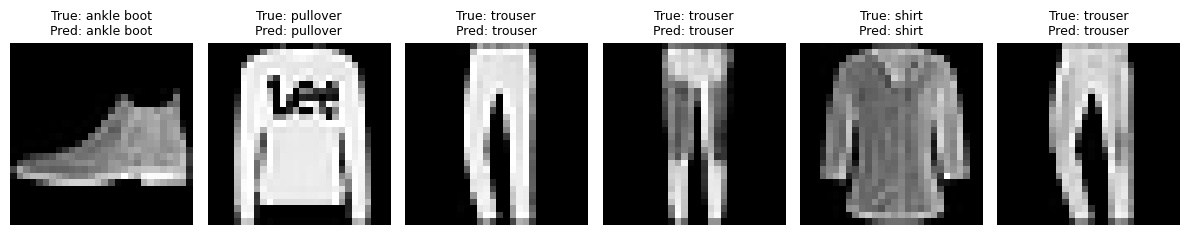

In [17]:
# d2l.predict_ch3(net, test_iter)
predict_ch3(net, test_iter)

## 小结

* 手动实现一个简单的多层感知机是很容易的。然而如果有大量的层，从零开始实现多层感知机会变得很麻烦（例如，要命名和记录模型的参数）。


[Discussions](https://discuss.d2l.ai/t/1804)
